<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/Midterm/air_quality_ml_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

Machine Learning - Midterm

October 9, 2026

The following notebook describes the analysis and findings for the class's midterm. The purpose of this assignment is to analyze a dataset on air pollutants and better understand contributing factors to each of these features. This dataset is located over UC Irvine's [Machine Learning Repository](https://archive.ics.uci.edu/dataset/360/air+quality). Our goals are:

- Use softmax/logistic and SGD classification to understand which variables are targets that the other features contribut to better understand.
- Take a regressional analysis of our chosen features to understand contributing factors.
- Use Lasso and Ridge Regression to understand changes to coefficients.

This notebook uses code and methods from the class [End-to-End Machine Learning Project](https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb), the Module 2 and Module 3 Overview for this class, the Module 2 and Module 3 videos, and Chapters 2 and 3 of our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)). This assignment uses code for regression analysis and visualization with the [Module 4 Environmental Trends Notebook](https://github.com/bforoura/ML26/blob/main/Module4_Regression/environmental_trends.ipynb).

Task 1 of this project is working in a Colab enterprise instance and a screenshot of proof shows the billing and credit balance at the bottom.

# Task 2: Loading the dataset

We will load this dataset programmatically by copying the code on the UC Irvine site.

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
air_quality = fetch_ucirepo(id=360)

# data (as pandas dataframes)
X = air_quality.data.features
y = air_quality.data.targets


In [ ]:
print(air_quality.data.features)

           Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
0     3/10/2004  18:00:00     2.6         1360       150      11.9   
1     3/10/2004  19:00:00     2.0         1292       112       9.4   
2     3/10/2004  20:00:00     2.2         1402        88       9.0   
3     3/10/2004  21:00:00     2.2         1376        80       9.2   
4     3/10/2004  22:00:00     1.6         1272        51       6.5   
...         ...       ...     ...          ...       ...       ...   
9352   4/4/2005  10:00:00     3.1         1314      -200      13.5   
9353   4/4/2005  11:00:00     2.4         1163      -200      11.4   
9354   4/4/2005  12:00:00     2.4         1142      -200      12.4   
9355   4/4/2005  13:00:00     2.1         1003      -200       9.5   
9356   4/4/2005  14:00:00     2.2         1071      -200      11.9   

      PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  \
0              1046      166          1056      113          1692   
1               955  

# Task 3: Inspection Methods

We will first use some inspection methods to get a sense of what this data looks like.

We first use `.head()` `.info()` to view the first 5 rows of this dataframe and their datatypes. We also use `.describe()` to understand the datatypes in our set.

In [ ]:
# Display the first 5 rows
display(X.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(X.info())
display(X.describe())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   int64  
 4   NMHC(GT)       9357 non-null   int64  
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   int64  
 7   NOx(GT)        9357 non-null   int64  
 8   PT08.S3(NOx)   9357 non-null   int64  
 9   NO2(GT)        9357 non-null   int64  
 10  PT08.S4(NO2)   9357 non-null   int64  
 11  PT08.S5(O3)    9357 non-null   int64  
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 1.1+ MB


None

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


# Task 4: Assessing Missing Values

The following uses methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation to inspect the dataframe for missing values and imputing values. We know that a number of variables have their blanks filled with -200. We should instead replace these with median values, as all of these values are numeric. We also take steps to drop the date and time variables as they describe more the observation.

 The following tutorials were helpful for reference:

- [Stack Overflow](https://stackoverflow.com/questions/59476179/is-it-possible-to-change-pandas-column-data-type-within-a-sklearn-pipeline) post describing how to change a datatype in a pipeline.

- [GeeksForGeeks](https://www.geeksforgeeks.org/pandas/pandas-strip-whitespace-from-entire-dataframe/) discussing how to strip white space from columns.

- [Pandas Documentation](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.replace.html) describing methods for replacing values in a dataframe. This is used to replace empty white space values with `np.nan`.

- [Geeks For Geeks](https://www.geeksforgeeks.org/python/how-to-convert-data-types-in-python-3/) describing how to convert data types.

- [Stack Overflow Article](https://stackoverflow.com/questions/43677933/converting-object-to-int-pandas) describing how to convert objects to int data types.

In [ ]:
#import the numpy library
import numpy as np

# Taking a copy of the dataframe to change it.
df_copy = X.copy()

#Dropping Date and Time Features
df_copy.drop(columns=['Date', 'Time'], inplace=True)

#Replacing -200 in all datatypes and replacing with the median.
df_copy['CO(GT)'] = df_copy['CO(GT)'].replace(-200, np.median(df_copy['CO(GT)']))
df_copy['CO(GT)'] = df_copy['CO(GT)'].replace(-200, np.median(df_copy['CO(GT)']))
df_copy['PT08.S1(CO)'] = df_copy['PT08.S1(CO)'].replace(-200, np.median(df_copy['PT08.S1(CO)']))
df_copy['NMHC(GT)'] = df_copy['NMHC(GT)'].replace(-200, np.median(df_copy['NMHC(GT)']))
df_copy[ 'C6H6(GT)'] = df_copy[ 'C6H6(GT)'].replace(-200, np.median(df_copy['C6H6(GT)']))
df_copy['PT08.S2(NMHC)'] = df_copy['PT08.S2(NMHC)'].replace(-200, np.median(df_copy['PT08.S2(NMHC)']))
df_copy['NOx(GT)'] = df_copy['NOx(GT)'].replace(-200, np.median(df_copy['NOx(GT)']))
df_copy['PT08.S3(NOx)'] = df_copy['PT08.S3(NOx)'].replace(-200, np.median(df_copy['PT08.S3(NOx)']))
df_copy['NO2(GT)'] = df_copy['NO2(GT)'].replace(-200, np.median(df_copy['NO2(GT)']))
df_copy['PT08.S4(NO2)'] = df_copy['PT08.S4(NO2)'].replace(-200, np.median(df_copy['PT08.S4(NO2)']))
df_copy['PT08.S5(O3)'] =  df_copy['PT08.S5(O3)'].replace(-200, np.median(df_copy['PT08.S5(O3)']))
df_copy['T'] = df_copy['T'].replace(-200, np.median(df_copy['T']))
df_copy['RH'] = df_copy['RH'].replace(-200, np.median(df_copy['RH']))
df_copy['AH'] = df_copy['AH'].replace(-200, np.median(df_copy['AH']))


Now, we can inspect the dataframe to see if we have imputed all the missing data. It appears that we have as all data has 9,357 entries.

In [ ]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CO(GT)         9357 non-null   float64
 1   PT08.S1(CO)    9357 non-null   int64  
 2   NMHC(GT)       9357 non-null   int64  
 3   C6H6(GT)       9357 non-null   float64
 4   PT08.S2(NMHC)  9357 non-null   int64  
 5   NOx(GT)        9357 non-null   int64  
 6   PT08.S3(NOx)   9357 non-null   int64  
 7   NO2(GT)        9357 non-null   int64  
 8   PT08.S4(NO2)   9357 non-null   int64  
 9   PT08.S5(O3)    9357 non-null   int64  
 10  T              9357 non-null   float64
 11  RH             9357 non-null   float64
 12  AH             9357 non-null   float64
dtypes: float64(5), int64(8)
memory usage: 950.4 KB


Here, we can inspect each variable and determine what kind of scaling we should apply to each distribution. We see that a number of variables have a large number of median values, likely due to the imputation.

array([[<Axes: title={'center': 'CO(GT)'}>,
        <Axes: title={'center': 'PT08.S1(CO)'}>,
        <Axes: title={'center': 'NMHC(GT)'}>,
        <Axes: title={'center': 'C6H6(GT)'}>],
       [<Axes: title={'center': 'PT08.S2(NMHC)'}>,
        <Axes: title={'center': 'NOx(GT)'}>,
        <Axes: title={'center': 'PT08.S3(NOx)'}>,
        <Axes: title={'center': 'NO2(GT)'}>],
       [<Axes: title={'center': 'PT08.S4(NO2)'}>,
        <Axes: title={'center': 'PT08.S5(O3)'}>,
        <Axes: title={'center': 'T'}>, <Axes: title={'center': 'RH'}>],
       [<Axes: title={'center': 'AH'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

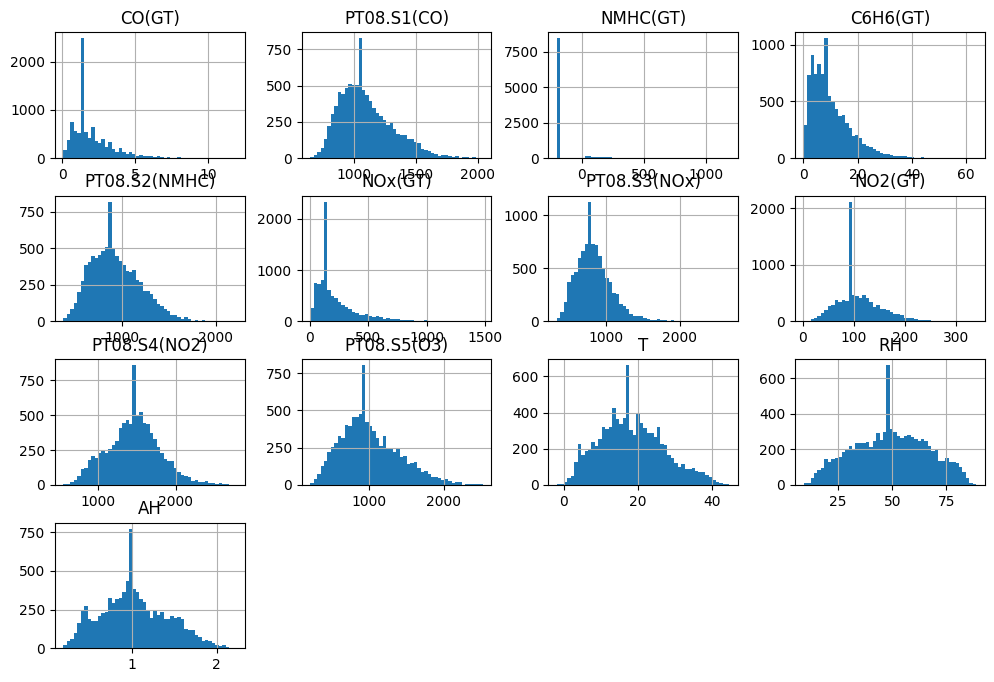

In [ ]:
df_copy.hist(bins=50, figsize=(12, 8))

It appears that most variables can likely be regularized with a standard or minmax scaler.

#Tasks 4, 5, and 6: Implementing Classifier and Pipeline

The following creates a pipeline for analysis. We are going to create two separate pipelines for the SGD Classifier that uses a min-max scaler or a standard scaler for numeric columns.

The following imports libraries necessary for this pipeline

In [ ]:
#Importing the method for a pipeline
from sklearn.pipeline import Pipeline
#Importing a simple imputer for filling empty values
from sklearn.impute import SimpleImputer
#Importing a one hot encoder for creating dummy variables for categorical data
from sklearn.preprocessing import OneHotEncoder
#Importing libraries for creating pipelines and a transformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
#Importing a Standard Scaler to standardize values.
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.preprocessing import FunctionTransformer

#Importing SGD Classifier
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split










Here, we can examine which target variables we should analyze further with a regression analysis.

The following is a function that creates a classification report for each target variable in our dataset. Target variables are binned to three categories: Low, Medium, High (0, 1, 2).

If we see high accuracy scores, this could indicate that other features could contribute to the variance in the target variable.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def run_classification_report(df_var, target_var):
  # Makes a copy of the dataframe
  df = df_var.copy()
  # Defines all features of the data set.
  feature_cols = ['CO(GT)','PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)',
        'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
        'T', 'RH', 'AH']
  # Removes the target variable from the list of column features
  feature_cols.remove(target_var)

  # Create a multi-class target variable for classification (3 bins: Low, Medium, High)
  #Using the following reference to re-ranking and help resolve issues with cutting: https://medium.com/@heyamit10/resolving-issues-with-duplicates-in-pandas-qcut-c589fdb56703
  df[target_var] = df_copy[target_var].replace(np.nan, np.median(df[target_var]))
  df[target_var] = pd.qcut(df[target_var].rank(method='first'), q=3, labels=['0', '1', '2'])
  df[target_var] = df[target_var].astype(int)

  # Define features and multi-class target
  X = df[feature_cols]
  y = df[target_var]

  # Split data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  # Create Softmax Regression Pipeline (Multinomial Logistic Regression)
  softmax_pipeline_standard = Pipeline([
      #Imputes the median for any missing values
      ('imputer', SimpleImputer(strategy='median')),
      #Applies a standard scaler
      ('scaler', StandardScaler()),
      #Applies a softmax classifier with 1000 iterations
      ('classifier', LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=42))
  ])

  softmax_pipeline_minmax = Pipeline([
      ('imputer', SimpleImputer(strategy='median')),
      ('scaler', MinMaxScaler()),
      ('classifier', LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=42))
  ])

  # Create Softmax Regression Pipeline (Multinomial Logistic Regression)
  sgd_pipeline_standard = Pipeline([
      ('imputer', SimpleImputer(strategy='median')),
      ('scaler', StandardScaler()),
      #Applies an SGD classifier with a log-loss function and 1000 iterations.
      ('classifier', SGDClassifier(loss='log_loss', max_iter=1000, random_state=42))
  ])

  sgd_pipeline_minmax = Pipeline([
      ('imputer', SimpleImputer(strategy='median')),
      ('scaler', MinMaxScaler()),
      ('classifier', SGDClassifier(loss='log_loss', max_iter=1000, random_state=42))
  ])

  # Fits each pipeline to the training data
  softmax_pipeline_standard.fit(X_train, y_train)
  softmax_pipeline_minmax.fit(X_train, y_train)
  sgd_pipeline_standard.fit(X_train, y_train)
  sgd_pipeline_minmax.fit(X_train, y_train)

  # Generates softmax and sgd predictions on the test set for standard scaling
  #and minmax scaling
  y_pred_softmax_standard = softmax_pipeline_standard.predict(X_test)
  y_pred_softmax_minmax = softmax_pipeline_minmax.predict(X_test)

  y_pred_sgd_standard = sgd_pipeline_standard.predict(X_test)
  y_pred_sgd_minmax = sgd_pipeline_minmax.predict(X_test)

  # Creates accuracy scores that are printed out.
  soft_max_accuracy_standard = accuracy_score(y_test, y_pred_softmax_standard)
  soft_max_accuracy_minmax = accuracy_score(y_test, y_pred_softmax_minmax)

  sgd_accuracy_standard = accuracy_score(y_test, y_pred_sgd_standard)
  sgd_accuracy_minmax = accuracy_score(y_test, y_pred_sgd_minmax)
  print(f"Target Variable {target_var}")
  print(f"Softmax Classification Test Accuracy (Standard): {soft_max_accuracy_standard:.4f}\n")
  print(f"Softmax Classification Test Accuracy (MinMax): {soft_max_accuracy_minmax:.4f}\n")

  print(f"SGD Classification Test Accuracy (Standard): {sgd_accuracy_standard:.4f}\n")
  print(f"SGD Classification Test Accuracy (MinMax): {sgd_accuracy_minmax:.4f}\n")

In [ ]:
feature_cols = ['CO(GT)','PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)',
        'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
        'T', 'RH', 'AH']
for i in feature_cols:
  run_classification_report(df_var=df_copy, target_var=i)



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Target Variable CO(GT)
Softmax Classification Test Accuracy (Standard): 0.7794

Softmax Classification Test Accuracy (MinMax): 0.7676

SGD Classification Test Accuracy (Standard): 0.7495

SGD Classification Test Accuracy (MinMax): 0.7511



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Target Variable PT08.S1(CO)
Softmax Classification Test Accuracy (Standard): 0.8285

Softmax Classification Test Accuracy (MinMax): 0.8232

SGD Classification Test Accuracy (Standard): 0.8109

SGD Classification Test Accuracy (MinMax): 0.8130



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


...

Target Variable T
Softmax Classification Test Accuracy (Standard): 0.9834

Softmax Classification Test Accuracy (MinMax): 0.9535

SGD Classification Test Accuracy (Standard): 0.9557

SGD Classification Test Accuracy (MinMax): 0.9343



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Target Variable RH
Softmax Classification Test Accuracy (Standard): 0.9001

Softmax Classification Test Accuracy (MinMax): 0.8825

SGD Classification Test Accuracy (Standard): 0.8841

SGD Classification Test Accuracy (MinMax): 0.8462



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Target Variable AH
Softmax Classification Test Accuracy (Standard): 0.9060

Softmax Classification Test Accuracy (MinMax): 0.9060

SGD Classification Test Accuracy (Standard): 0.8889

SGD Classification Test Accuracy (MinMax): 0.8910



Using this classification, we can see that a number of variables have a high accuracy for classification: `C6H6(GT)`,`PT08.S2(NMHC)`,`T`,
`RH`,`AH`. T or Temperature would make sense as a target variable as we can analyze how pollutants contribut to increases in temperature. The highest classification scores appear to follow with Benzene concentration `C6H6(GT)`, Carbon Monoxide concentration `PT08.S2(NMHC)`, and temperature, `T`. We will analyze these three variables for regression analysis.

# Task 7: Comparing Linear Regression, Ridge, and Lasso Regression


The following visualizes Linear Regression, Ridge, and Lasso regression using methods from the following notebook [Module 4 Environmental Trends Notebook](https://github.com/bforoura/ML26/blob/main/Module4_Regression/environmental_trends.ipynb). First, SGD, Ridge, and Lasso coefficients are printed. Second, they are visualized in comparison to a best-fit line. Third, we graph alphas for Ridge and Lasso to see how the models change with varying penalty scores.  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import SGDRegressor

def run_regression_report(df_var, target_var):

  # Makes a copy of the dataframe
  df = df_var.copy()
  # Define features and target variable
  feature_cols = ['CO(GT)','PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)',
        'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
        'T', 'RH', 'AH']

  feature_cols.remove(target_var)

  # Define features and target variables
  X = df[feature_cols]
  y = df[target_var]

  # Create SGD Regression Pipeline (Standard)
  sgd_pipeline_standard = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', SGDRegressor(max_iter=1000, tol=1e-3, learning_rate='invscaling', eta0=0.01, random_state=42))
  ])

  # Create Ridge Regression Pipeline (L2 Regularization) (Standard)
  ridge_pipeline_standard = Pipeline([
      ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
      ('scaler', StandardScaler()),
      ('regressor', Ridge(alpha=1.0, random_state=42))
  ])

  # Create Lasso Regression Pipeline (L1 Regularization) (Standard)
  lasso_pipeline_standard = Pipeline([
      ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
      ('scaler', StandardScaler()),
      ('regressor', Lasso(alpha=0.1, max_iter=5000, random_state=42))
  ])

  # Create SGD Regression Pipeline (Minmax)
  sgd_pipeline_minmax = Pipeline([
    ('scaler', MinMaxScaler()),
    ('regressor', SGDRegressor(max_iter=1000, tol=1e-3, learning_rate='invscaling', eta0=0.01, random_state=42))
  ])

  # Create Ridge Regression Pipeline (L2 Regularization) (Minmax)
  ridge_pipeline_minmax = Pipeline([
      ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
      ('scaler', MinMaxScaler()),
      ('regressor', Ridge(alpha=1.0, random_state=42))
  ])

  # Create Lasso Regression Pipeline (L1 Regularization) (Minmax)
  lasso_pipeline_minmax = Pipeline([
      ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
      ('scaler', MinMaxScaler()),
      ('regressor', Lasso(alpha=0.1, max_iter=5000, random_state=42))
  ])

  # Fit both pipelines
  sgd_pipeline_standard.fit(X, y)
  ridge_pipeline_standard.fit(X, y)
  lasso_pipeline_standard.fit(X, y)

  sgd_pipeline_minmax.fit(X, y)
  ridge_pipeline_minmax.fit(X, y)
  lasso_pipeline_minmax.fit(X, y)

  # Generate predictions
  y_pred_sgd_standard = sgd_pipeline_standard.predict(X)
  y_pred_ridge_standard = ridge_pipeline_standard.predict(X)
  y_pred_lasso_standard = lasso_pipeline_standard.predict(X)

  # Generate predictions
  y_pred_sgd_minmax = sgd_pipeline_minmax.predict(X)
  y_pred_ridge_minmax = ridge_pipeline_minmax.predict(X)
  y_pred_lasso_minmax = lasso_pipeline_minmax.predict(X)

  # Evaluate SGD
  sgd_rmse_standard = np.sqrt(mean_squared_error(y, y_pred_sgd_standard))
  sgd_r2_standard = r2_score(y, y_pred_sgd_standard)

  sgd_rmse_minmax = np.sqrt(mean_squared_error(y, y_pred_sgd_minmax))
  sgd_r2_minmax = r2_score(y, y_pred_sgd_minmax)

  # Evaluate Ridge
  ridge_rmse_standard = np.sqrt(mean_squared_error(y, y_pred_ridge_standard))
  ridge_r2_standard = r2_score(y, y_pred_ridge_standard)

  ridge_rmse_minmax = np.sqrt(mean_squared_error(y, y_pred_ridge_minmax))
  ridge_r2_minmax = r2_score(y, y_pred_ridge_minmax)

  # Evaluate Lasso
  lasso_rmse_standard = np.sqrt(mean_squared_error(y, y_pred_lasso_standard))
  lasso_r2_standard = r2_score(y, y_pred_lasso_standard)

  lasso_rmse_minmax = np.sqrt(mean_squared_error(y, y_pred_lasso_minmax))
  lasso_r2_minmax = r2_score(y, y_pred_lasso_minmax)

  print("\nSGD Regression (L2) Metrics (Standard Scaling):")
  print(f"RMSE: {sgd_rmse_standard:.4f} | R2: {sgd_r2_standard:.4f}")
  # Retrieve coefficients from the Regressor step
  trained_regressor = sgd_pipeline_standard.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")


  print("\nRidge Regression (L2) Metrics (Standard Scaling):")
  print(f"RMSE: {ridge_rmse_standard:.4f} | R2: {ridge_r2_standard:.4f}")
  # Retrieve coefficients from the Regressor step
  trained_regressor = ridge_pipeline_standard.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")

  print("\nLasso Regression (L1) Metrics (Standard Scaling):")
  print(f"RMSE: {lasso_rmse_standard:.4f} | R2: {lasso_r2_standard:.4f}")
  # Retrieve coefficients from the Regressor step
  trained_regressor = lasso_pipeline_standard.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")

  print("\nSGD Regression (L1) Metrics (Minmax Scaling):")
  print(f"RMSE: {sgd_rmse_minmax:.4f} | R2: {sgd_r2_minmax:.4f}")
  # Retrieve coefficients from the Regressor step
  trained_regressor = sgd_pipeline_minmax.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")

  print("\nRidge Regression (L2) Metrics (Minmax Scaling):")
  print(f"RMSE: {ridge_rmse_minmax:.4f} | R2: {ridge_r2_minmax:.4f}")
  trained_regressor = ridge_pipeline_minmax.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")

  print("\nLasso Regression (L1) Metrics (Minmax Scaling):")
  print(f"RMSE: {lasso_rmse_standard:.4f} | R2: {lasso_r2_standard:.4f}")
  trained_regressor = lasso_pipeline_minmax.named_steps['regressor']
  for feature, coef in zip(feature_cols, trained_regressor.coef_):
    print(f"{feature}: {coef:.4f}")


  # Visualize regularized predictions vs Actual (Standard)
  plt.figure(figsize=(9, 5))
  plt.scatter(y, y_pred_sgd_standard, color='darkgreen', alpha=0.5, label='SGD Predictions')
  plt.scatter(y, y_pred_ridge_standard, color='royalblue', alpha=0.5, label='Ridge Predictions')
  plt.scatter(y, y_pred_lasso_standard, color='darkorange', alpha=0.5, label='Lasso Predictions')

  min_val = min(y.min(), y_pred_ridge_standard.min(), y_pred_lasso_standard.min())
  max_val = max(y.max(), y_pred_ridge_standard.max(), y_pred_lasso_standard.max())
  plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

  plt.xlabel(f'Actual {target_var}')
  plt.ylabel(f'Predicted {target_var}')
  plt.title(f'Regularized Models (Ridge vs. Lasso) (Standard Scaling): Actual vs. Predicted {target_var}')
  plt.legend()
  plt.show()

  # Visualize regularized predictions vs Actual (Minmax)
  plt.figure(figsize=(9, 5))
  plt.scatter(y, y_pred_sgd_minmax, color='darkgreen', alpha=0.5, label='SGD Predictions')
  plt.scatter(y, y_pred_ridge_minmax, color='royalblue', alpha=0.5, label='Ridge Predictions')
  plt.scatter(y, y_pred_lasso_minmax, color='darkorange', alpha=0.5, label='Lasso Predictions')

  min_val = min(y.min(), y_pred_ridge_minmax.min(), y_pred_lasso_minmax.min())
  max_val = max(y.max(), y_pred_ridge_minmax.max(), y_pred_lasso_minmax.max())
  plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

  plt.xlabel(f'Actual {target_var}')
  plt.ylabel(f'Predicted {target_var}')
  plt.title(f'Regularized Models (Ridge vs. Lasso) (Minmax Scaling): Actual vs. Predicted {target_var}')
  plt.legend()
  plt.show()

  alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

  ridge_rmses_standard = []
  lasso_rmses_standard = []

  ridge_rmses_minmax = []
  lasso_rmses_minmax = []

  # Evaluate Ridge and Lasso across alpha values
  for a in alpha_values:
      ridge_exp_standard = Pipeline([
          ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
          ('scaler', StandardScaler()),
          ('regressor', Ridge(alpha=a, random_state=42))
      ])
      ridge_exp_standard.fit(X, y)
      ridge_rmses_standard.append(np.sqrt(mean_squared_error(y, ridge_exp_standard.predict(X))))

      lasso_exp_standard = Pipeline([
          ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
          ('scaler', StandardScaler()),
          ('regressor', Lasso(alpha=a, max_iter=5000, random_state=42))
      ])
      lasso_exp_standard.fit(X, y)
      lasso_rmses_standard.append(np.sqrt(mean_squared_error(y, lasso_exp_standard.predict(X))))

      ridge_exp_minmax = Pipeline([
          ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
          ('scaler', MinMaxScaler()),
          ('regressor', Ridge(alpha=a, random_state=42))
      ])
      ridge_exp_minmax.fit(X, y)
      ridge_rmses_minmax.append(np.sqrt(mean_squared_error(y, ridge_exp_minmax.predict(X))))

      lasso_exp_minmax = Pipeline([
          ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
          ('scaler', MinMaxScaler()),
          ('regressor', Lasso(alpha=a, max_iter=5000, random_state=42))
      ])
      lasso_exp_minmax.fit(X, y)
      lasso_rmses_minmax.append(np.sqrt(mean_squared_error(y, lasso_exp_minmax.predict(X))))
  # Plotting the alpha effects
  plt.figure(figsize=(9, 5))
  plt.plot(alpha_values, ridge_rmses_standard, 'bo-', linewidth=2, label='Ridge RMSE')
  plt.plot(alpha_values, lasso_rmses_standard, 'ro--', linewidth=2, label='Lasso RMSE')
  plt.xscale('log')
  plt.xlabel('Alpha (Regularization Strength)')
  plt.ylabel(f'RMSE {target_var}')
  plt.title(f'Effect of Alpha Hyperparameter on Ridge and Lasso RMSE {target_var} (Standard Scaling)')
  plt.legend()
  plt.grid(True)
  plt.show()

  # Plotting the alpha effects
  plt.figure(figsize=(9, 5))
  plt.plot(alpha_values, ridge_rmses_minmax, 'bo-', linewidth=2, label='Ridge RMSE')
  plt.plot(alpha_values, lasso_rmses_minmax, 'ro--', linewidth=2, label='Lasso RMSE')
  plt.xscale('log')
  plt.xlabel('Alpha (Regularization Strength)')
  plt.ylabel(f'RMSE {target_var}')
  plt.title(f'Effect of Alpha Hyperparameter on Ridge and Lasso RMSE {target_var} (MinMax Scaling)')
  plt.legend()
  plt.grid(True)
  plt.show()

The following cell runs a regression report on each variable: benzene concentration `C6H6(GT)`, carbon monoxide concentration `PT08.S2(NMHC)`, and temperature `T`


SGD Regression (L2) Metrics (Standard Scaling):
RMSE: 1.1333 | R2: 0.9760
CO(GT): 0.4216
PT08.S1(CO): 0.4564
NMHC(GT): -0.2396
PT08.S2(NMHC): 7.4308
NOx(GT): 0.2457
PT08.S3(NOx): 1.0440
NO2(GT): -0.4328
PT08.S4(NO2): 0.1153
PT08.S5(O3): -0.0512
T: -0.8321
RH: -0.4115
AH: 0.4335

Ridge Regression (L2) Metrics (Standard Scaling):
RMSE: 0.0300 | R2: 1.0000
CO(GT): 0.0541
PT08.S1(CO): 0.0190
NMHC(GT): 0.0154
PT08.S2(NMHC): 0.6427
NOx(GT): 0.0219
PT08.S3(NOx): 0.0123
NO2(GT): -0.0390
PT08.S4(NO2): 0.0641
PT08.S5(O3): 0.0742
T: -0.0265
RH: -0.0405
AH: -0.0432

Lasso Regression (L1) Metrics (Standard Scaling):
RMSE: 0.1472 | R2: 0.9996
CO(GT): 0.0000
PT08.S1(CO): 0.0000
NMHC(GT): 0.0000
PT08.S2(NMHC): 0.0000
NOx(GT): 0.0000
PT08.S3(NOx): -0.0000
NO2(GT): 0.0000
PT08.S4(NO2): 0.0000
PT08.S5(O3): 0.0000
T: 0.0000
RH: -0.0000
AH: 0.0000

SGD Regression (L1) Metrics (Minmax Scaling):
RMSE: 1.3425 | R2: 0.9663
CO(GT): 5.6434
PT08.S1(CO): 5.1417
NMHC(GT): -4.3585
PT08.S2(NMHC): 30.5183
NOx(GT): 4.

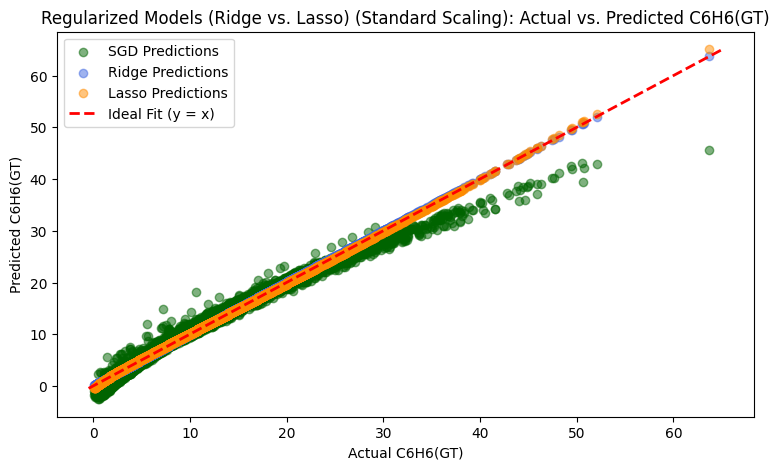

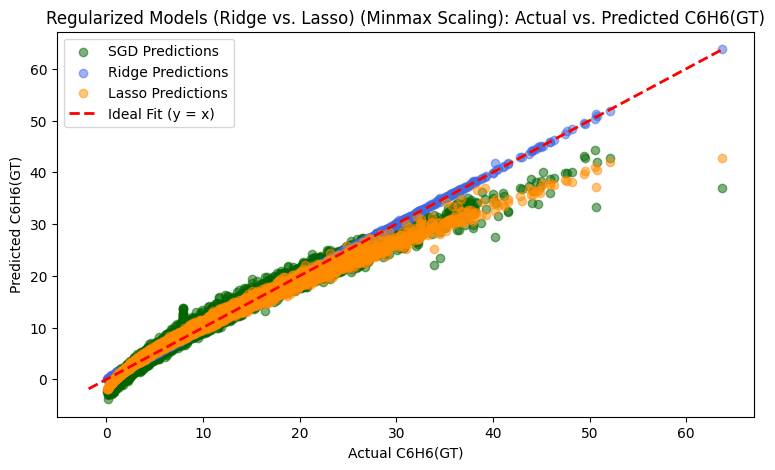

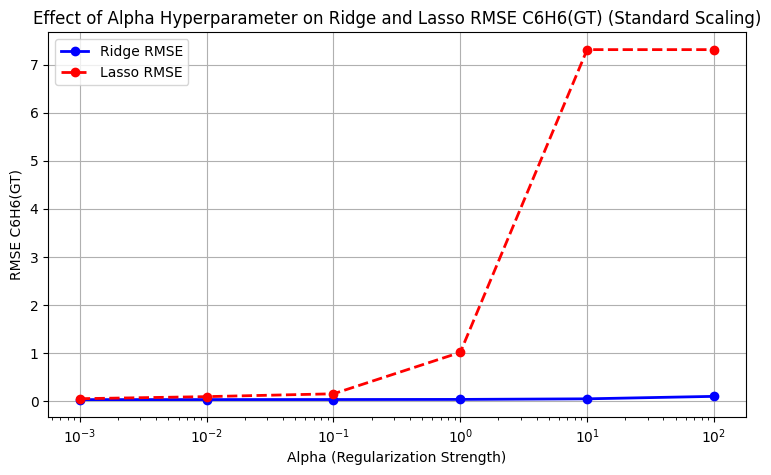

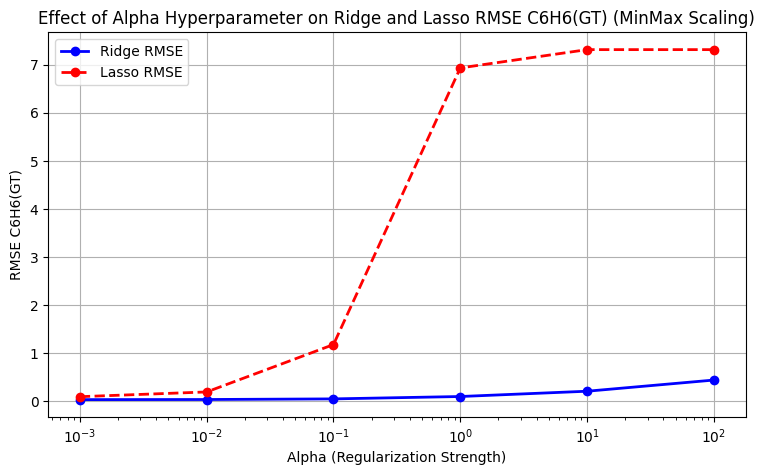


SGD Regression (L2) Metrics (Standard Scaling):
RMSE: 32.6268 | R2: 0.9845
CO(GT): -5.2339
PT08.S1(CO): 0.3649
NMHC(GT): 0.8738
C6H6(GT): 174.7127
NOx(GT): 5.7641
PT08.S3(NOx): -41.9950
NO2(GT): 5.9574
PT08.S4(NO2): 44.6368
PT08.S5(O3): 18.4120
T: 19.4285
RH: -0.3727
AH: -29.3273

Ridge Regression (L2) Metrics (Standard Scaling):
RMSE: 1.9492 | R2: 0.9999
CO(GT): 12.9995
PT08.S1(CO): 13.3221
NMHC(GT): 3.5955
C6H6(GT): 51.8710
NOx(GT): 8.9180
PT08.S3(NOx): -18.8666
NO2(GT): 10.3986
PT08.S4(NO2): 16.7360
PT08.S5(O3): 15.6587
T: 4.0294
RH: -8.7467
AH: -2.3715

Lasso Regression (L1) Metrics (Standard Scaling):
RMSE: 5.2519 | R2: 0.9996
CO(GT): 0.0000
PT08.S1(CO): 2.4496
NMHC(GT): 0.0000
C6H6(GT): 182.6229
NOx(GT): 1.7983
PT08.S3(NOx): -30.8579
NO2(GT): 5.1229
PT08.S4(NO2): 8.8881
PT08.S5(O3): 11.4657
T: 0.0000
RH: -0.0000
AH: 0.0000

SGD Regression (L1) Metrics (Minmax Scaling):
RMSE: 33.6234 | R2: 0.9835
CO(GT): -9.2027
PT08.S1(CO): 53.5474
NMHC(GT): -26.0203
C6H6(GT): 1268.1092
NOx(GT):

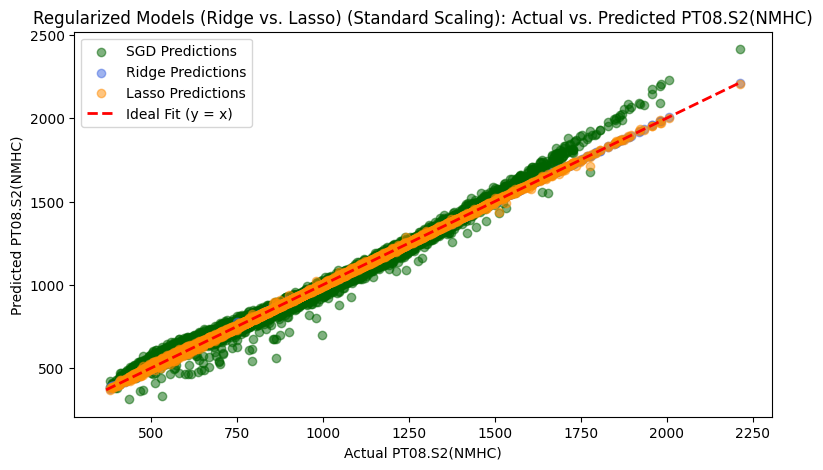

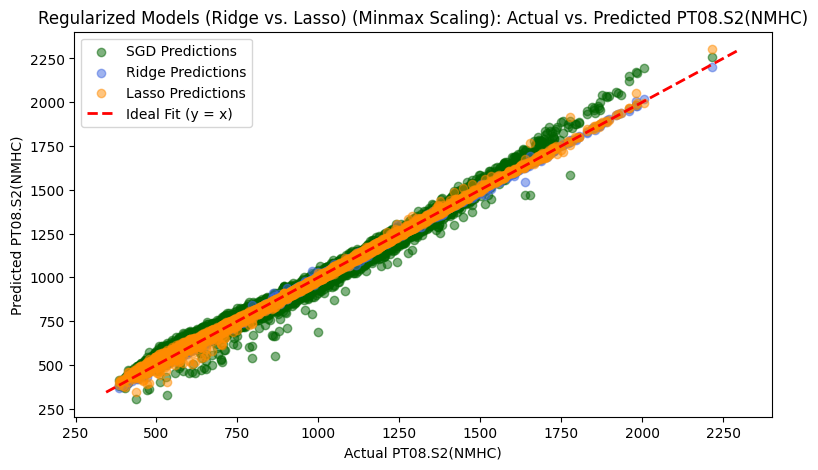

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.351e+04, tolerance: 6.408e+04
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.596e+04, tolerance: 6.408e+04
  model = cd_fast.enet_coordinate_descent(


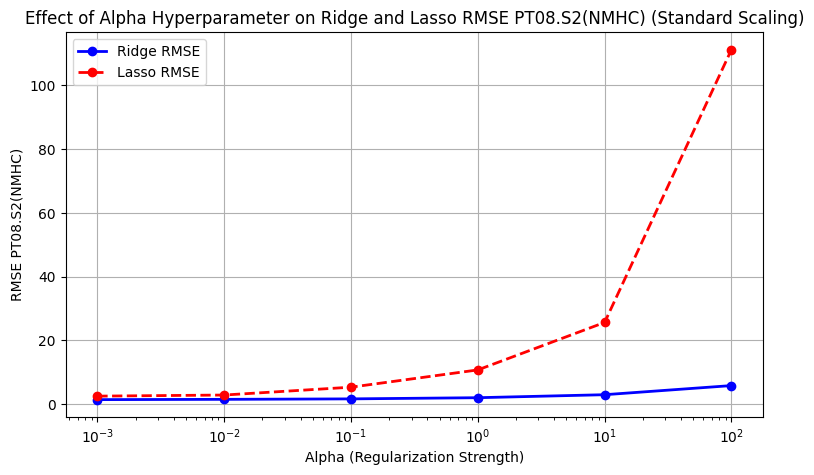

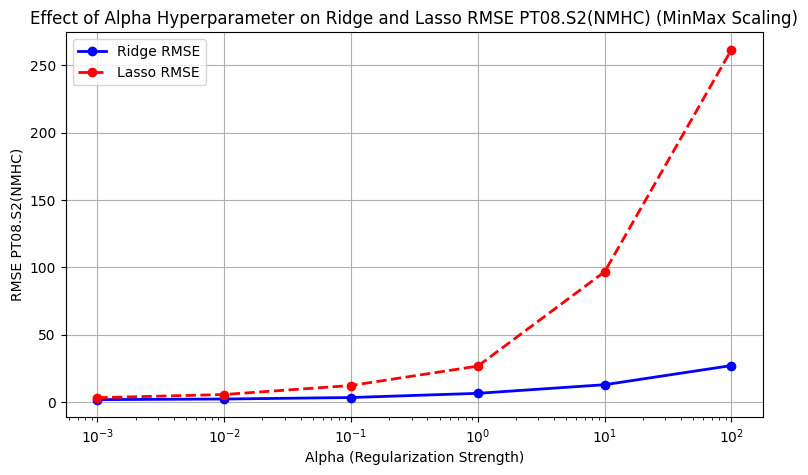


SGD Regression (L2) Metrics (Standard Scaling):
RMSE: 2.2764 | R2: 0.9309
CO(GT): -0.2880
PT08.S1(CO): 0.2751
NMHC(GT): -0.2894
C6H6(GT): -2.2678
PT08.S2(NMHC): 2.0343
NOx(GT): 0.3075
PT08.S3(NOx): 0.1403
NO2(GT): -0.0420
PT08.S4(NO2): 2.0213
PT08.S5(O3): -1.0383
RH: -5.7810
AH: 5.4702

Ridge Regression (L2) Metrics (Standard Scaling):
RMSE: 0.1691 | R2: 0.9996
CO(GT): -0.0947
PT08.S1(CO): 0.3008
NMHC(GT): -0.1647
C6H6(GT): 0.0826
PT08.S2(NMHC): 0.3200
NOx(GT): -0.2781
PT08.S3(NOx): -0.5951
NO2(GT): -0.2099
PT08.S4(NO2): 1.0934
PT08.S5(O3): -0.3673
RH: -3.3205
AH: 3.2845

Lasso Regression (L1) Metrics (Standard Scaling):
RMSE: 1.3281 | R2: 0.9765
CO(GT): -0.0000
PT08.S1(CO): 0.0000
NMHC(GT): -0.0000
C6H6(GT): 0.0000
PT08.S2(NMHC): 0.0000
NOx(GT): -0.0000
PT08.S3(NOx): -0.0000
NO2(GT): -0.0000
PT08.S4(NO2): 0.4516
PT08.S5(O3): -0.0000
RH: -4.0365
AH: 4.0174

SGD Regression (L1) Metrics (Minmax Scaling):
RMSE: 2.3174 | R2: 0.9284
CO(GT): -1.3602
PT08.S1(CO): -0.5897
NMHC(GT): -2.9865
C6

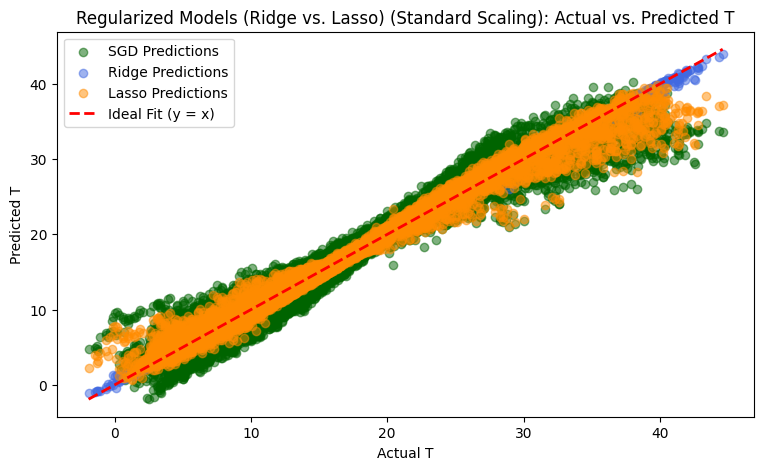

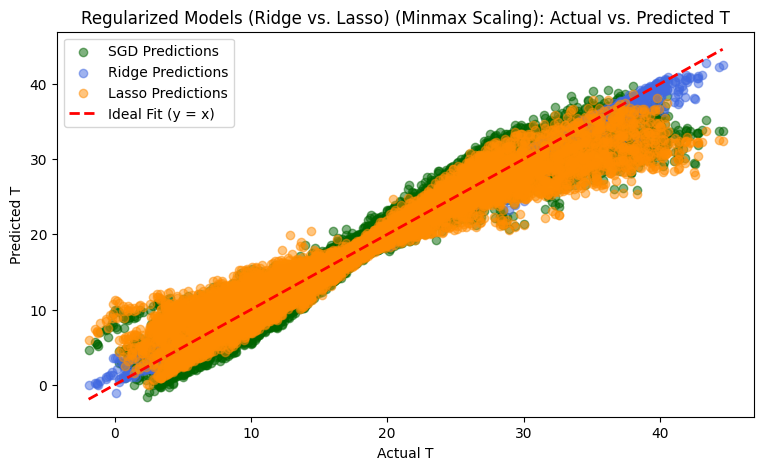

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.127e+02, tolerance: 7.017e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.297e+02, tolerance: 7.017e+01
  model = cd_fast.enet_coordinate_descent(


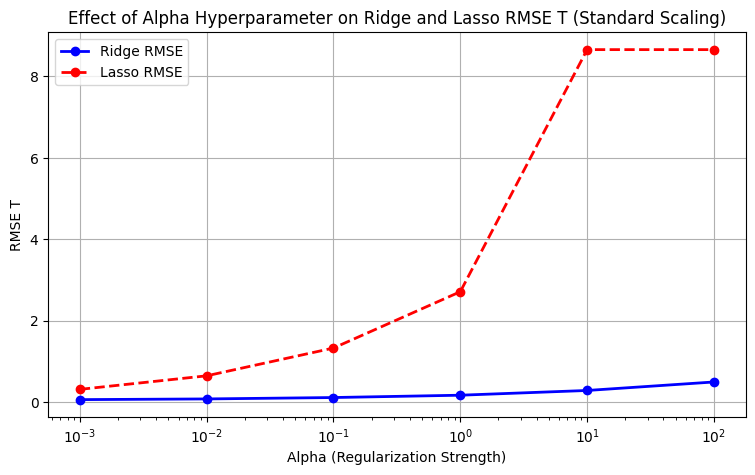

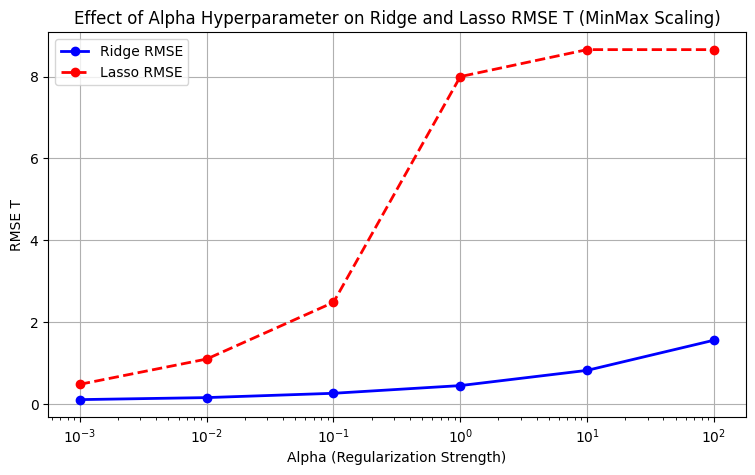

In [ ]:
feature_cols = ['C6H6(GT)','PT08.S2(NMHC)','T']
for i in feature_cols:
  run_regression_report(df_var=df_copy, target_var=i)

# Task 8

This notebook was executed in Google Colab. The following is a screenshot of the billing statement used to run this session.

![billing](https://github.com/mf1060/ml-2026/blob/main/Midterm/colab-billing-report.jpg)

This is also a [link](https://github.com/mf1060/ml-2026/blob/main/Midterm/colab-billing-report.jpg) to the image.